In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.linalg import lu_factor, lu_solve
from scipy.optimize import brentq
from IPython.display import HTML


E = 200e9
rho = 7800
B, H = 0.01, 0.01
J = B * H**3 / 12
a_sq = E * J / (rho * B * H)
a = np.sqrt(a_sq)
f1_target = 440.0
L = 0.1363
h = 0.001
N_modes = 8

In [ ]:
# D_n — корни cosh(D)cos(D) = -1

char_eq = lambda D: np.cosh(D) * np.cos(D) + 1

D_n = np.array([brentq(char_eq, (2*k+1)*np.pi/2 - 1, (2*k+1)*np.pi/2 + 1)
                for k in range(N_modes)])

beta_n = D_n / L
omega_n = a * beta_n**2


def X_mode(x, n):
    bx = beta_n[n] * x
    bL = D_n[n]
    sigma = (np.cos(bL) + np.cosh(bL)) / (np.sin(bL) + np.sinh(bL))
    return (np.cosh(bx) - np.cos(bx)) - sigma * (np.sinh(bx) - np.sin(bx))


# НУ: статический прогиб консоли (сила на конце, отклонение h)
def y_static(x):
    return h * (3 * x**2 / (2 * L**2) - x**3 / (2 * L**3))


# C_n 
def compute_Cn(x):
    y0 = y_static(x)
    C = np.zeros(N_modes)
    for n in range(N_modes):
        Xn = X_mode(x, n)
        C[n] = np.trapz(y0 * Xn, x) / np.trapz(Xn**2, x)
    return C


# y(x,t) = sum C_n * X_n(x) * cos(omega_n * t)
def y_semi(x, t, C):
    result = np.zeros((len(x), len(t)))
    for n in range(N_modes):
        Xn = X_mode(x, n)
        result += C[n] * np.outer(Xn, np.cos(omega_n[n] * t))
    return result

In [ ]:
def solve_beam_implicit(x, t, Y0, a_sq):
    Nx, Nt = len(x), len(t)
    dx = x[1] - x[0]
    dt = t[1] - t[0]
    r = a_sq * dt**2 / dx**4

    y = np.zeros((Nx, Nt))
    y[:, 0] = Y0
    y[:, 1] = Y0

    A = np.zeros((Nx, Nx))
    for i in range(2, Nx - 2):
        A[i, i-2:i+3] = [r, -4*r, 1 + 6*r, -4*r, r]

    # ГУ: заделка (x=0): y=0, y'=0
    A[0, 0] = 1
    A[1, 0], A[1, 1] = -1, 1
    # ГУ: свободный конец (x=L): y''=0, y'''=0
    A[-1, -3:] = [1, -2, 1]
    A[-2, -4:] = [-1, 3, -3, 1]

    lu_piv = lu_factor(A)
    for j in range(1, Nt - 1):
        B = 2*y[:, j] - y[:, j-1]
        B[0] = 0
        B[1] = 0
        B[-1] = 0
        B[-2] = 0
        y[:, j+1] = lu_solve(lu_piv, B)
    return y

In [4]:
Nx = 1200
Nt = 16000
t_max = 8.0 / f1_target

x_num = np.linspace(0, L, Nx)
t_eval = np.linspace(0, t_max, Nt)

Y0 = y_static(x_num)
Y0[0], Y0[1] = 0, 0

C_coeffs = compute_Cn(x_num)

y_num = solve_beam_implicit(x_num, t_eval, Y0, a_sq)
y_an = y_semi(x_num, t_eval, C_coeffs)

C:\Users\admin\AppData\Local\Temp\ipykernel_25296\2002391312.py:37: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  C[n] = np.trapz(y0 * Xn, x) / np.trapz(Xn**2, x)


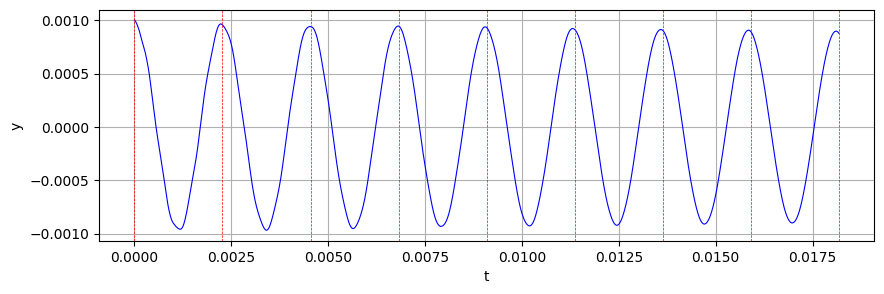

In [21]:
signal = y_num[-1, :]
T1 = 1 / 440

plt.figure(figsize=(10, 3))
plt.plot(t_eval, signal, 'b-', lw=0.8)
for k in range(int(t_max / T1) + 1):
    plt.axvline(k * T1, color='r', ls='--', lw=0.5)
plt.xlabel('t')
plt.ylabel('y')
plt.grid(True)
plt.show()

In [ ]:
step = 15
n_frames = (Nt - 1) // step + 1

fig, ax = plt.subplots(figsize=(10, 5))
line_an,  = ax.plot(x_num, y_an[:, 0], 'g-', lw=2, label='Полуаналитическое')
line_num, = ax.plot(x_num, y_num[:, 0], 'r--', lw=1.5, label='Числ. схема')
ax.set_xlim(0, L)
ym = max(np.max(np.abs(y_an)), np.max(np.abs(y_num)))
ax.set_ylim(-1.15 * ym, 1.15 * ym)
ax.set_xlabel('$x$ (м)')
ax.set_ylabel('$y(x,t)$ (м)')
ax.legend()
ax.grid(True, alpha=0.3)

def animate(k):
    j = min(k * step, Nt - 1)
    line_an.set_ydata(y_an[:, j])
    line_num.set_ydata(y_num[:, j])
    ax.set_title(f'$t = {t_eval[j]:.4f}$ с')
    return line_an, line_num

anim = FuncAnimation(fig, animate, frames=n_frames, interval=80, blit=True, repeat=True)
plt.tight_layout()
plt.close(fig)
HTML(anim.to_jshtml())

Animation size has reached 20996898 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
